In [243]:
# Requires Diplib2 conda interpreter
import os
from os.path import dirname, join, basename
cwd = os.getcwd()
import sys
import warnings
warnings.filterwarnings('ignore')
import re
import ddeq
from pathlib import Path

from math import prod
import numpy as np
import xarray as xr
import pandas as pd
from scipy.spatial import KDTree
from scipy.stats import norm
from scipy.optimize import least_squares,minimize, NonlinearConstraint, root
from scipy.interpolate import SmoothSphereBivariateSpline, CubicSpline, PchipInterpolator
from scipy.sparse import diags, dia_matrix
from sklearn.mixture import GaussianMixture
from sklearn.metrics import r2_score

#import xesmf as xe
import cartopy.crs as ccrs
from netCDF4 import Dataset
import ucat
import numpy.ma as ma
from tqdm import tqdm
from shapely.geometry import Point, Polygon
from cartopy.geodesic import Geodesic
Earth = Geodesic(radius=6378137.0)

import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 300

CRS = ccrs.UTM(32)
WGS84 = ccrs.PlateCarree()

DOMAIN = ddeq.misc.Domain.from_nml(join(dirname(ddeq.__file__), 'data', 'INPUT_ORG'))

#ROOT = f'{cwd}'

SMARTCARB_DATA_PATH = join(cwd, 'SMARTCARB')
SMARTCARB_FILES = [join('SMARTCARB',file) for file in os.listdir(SMARTCARB_DATA_PATH) 
                   if file.endswith('.nc')]
WIND_DATA_PATH = join(cwd, 'SMARTCARB_winds')

In [2]:
day = pd.Timestamp(year=2015,month=12,day=10)
l2 = ddeq.smartcarb.Level2Dataset(SMARTCARB_DATA_PATH,'ace',co2_noise_scenario='medium',no2_noise_scenario='high',
                                  make_no2_error_cloud_dependent=False,co2_cloud_threshold=1.0,no2_cloud_threshold=1.0)
data_for_day = l2.read_date(day)
print('Number of dataset:', len(data_for_day))
overpass = data_for_day[0]
overpass

Number of dataset: 2


<xarray.Dataset> Size: 8MB
Dimensions:  (nobs: 811, nrows: 123, ncorners: 4)
Dimensions without coordinates: nobs, nrows, ncorners
Data variables: (12/14)
    time     datetime64[ns] 8B 2015-12-10T11:00:00
    lon      (nobs, nrows) float32 399kB 11.35 11.39 11.42 ... 8.466 8.493 8.519
    lat      (nobs, nrows) float32 399kB 60.54 60.54 60.53 ... 46.03 46.03 46.02
    lonc     (nobs, nrows, ncorners) float32 2MB 11.33 11.37 ... 8.529 8.502
    latc     (nobs, nrows, ncorners) float32 2MB 60.55 60.55 ... 46.01 46.02
    clouds   (nobs, nrows) float32 399kB nan nan nan nan nan ... nan nan nan nan
    ...       ...
    NO2_BG   (nobs, nrows) float32 399kB nan nan nan nan nan ... nan nan nan nan
    CO_BG    (nobs, nrows) float32 399kB nan nan nan nan nan ... nan nan nan nan
    CO2      (nobs, nrows) float32 399kB nan nan nan nan nan ... nan nan nan nan
    CO2_std  (nobs, nrows) float32 399kB 0.7 0.7 0.7 0.7 0.7 ... 0.7 0.7 0.7 0.7
    NO2      (nobs, nrows) float32 399kB nan nan nan nan nan ... nan nan nan nan
    NO2_std  (nobs, nrows) float32 399kB 2e+15 2e+15 2e+15 ... 2e+15 2e+15 2e+15
Attributes:
    satellite:    CO2M
    orbit:        5114
    lon_eq:       0
    DESCRIPTION:  Synthetic XCO2 and NO2 satellite image with auxiliary data ...
    DATAORIGIN:   SMARTCARB study
    DOI:          10.5281/zenodo.4048227
    CREATOR:      Gerrit Kuhlmann et al.
    EMAIL:        gerrit.kuhlmann@empa.ch
    AFFILIATION:  Empa Duebendorf, Switzerland

In [3]:
def compute_along_track(overpass):
    center_lon = overpass['lon'].mean(dim='nrows').data
    #center_lat = overpass['lat'].mean(dim='nrows').data
    along_track_coords = np.full((overpass.dims['nobs'],2),np.nan,dtype=np.float32)
    for nobs in range(overpass.dims['nobs']):
        spl = PchipInterpolator(overpass['lon'][nobs,:].data,overpass['lat'][nobs,:].data)
        along_track_coords[nobs] = [center_lon[nobs],spl(center_lon[nobs])]
    return along_track_coords

def plot_overpass(overpass):
    along_track_coords = compute_along_track(overpass)
    fig = plt.figure(figsize=(8,5))
    scatter = plt.scatter(overpass['lon'][:,:].data.flatten(),overpass['lat'][:,:].data.flatten(),
                          c=overpass['CO2'][:,:].data.flatten(),cmap="RdYlBu_r",marker='s',s=0.5,)
    cbar = plt.colorbar(mappable=scatter)
    cbar.ax.set_title('ppm')
    plt.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
             linestyle='-',color='black',linewidth=0.5)
    plt.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
             linestyle='-',color='black',linewidth=0.5)
    plt.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
             linestyle='-',color='black',linewidth=0.5)
    plt.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
             linestyle='-',color='black',linewidth=0.5)
    plt.plot(along_track_coords[:,0],along_track_coords[:,1],linestyle='--',color='black',linewidth=0.5)
    #plt.plot(center_lon,center_lat,linestyle='--',color='red',linewidth=0.5)
    plt.xlabel('longitude (°)')
    plt.ylabel('latitude (°)')
    plt.show()

# Remove all observations lines where there are only nans
def remove_nan_lines(overpass,key='CO2'):
    # Variables without dimensions
    variables = [variable for variable in overpass.variables if overpass[variable].ndim == 0]
    temp = overpass.drop_vars(variables)
    non_nans = ~np.isnan(overpass[key])
    bool_xarray = non_nans.any(dim='nrows')
    temp = temp.where(bool_xarray,drop=True)
    for variable in variables:
        temp[variable] = overpass[variable]
    return temp

overpass = remove_nan_lines(overpass)
overpass

<xarray.Dataset> Size: 3MB
Dimensions:  (nobs: 364, nrows: 123, ncorners: 4)
Dimensions without coordinates: nobs, nrows, ncorners
Data variables: (12/14)
    lon      (nobs, nrows) float32 179kB 9.013 9.046 9.079 ... 9.752 9.78 9.808
    lat      (nobs, nrows) float32 179kB 55.98 55.97 55.97 ... 49.2 49.2 49.19
    lonc     (nobs, nrows, ncorners) float32 716kB 9.001 9.034 ... 9.819 9.79
    latc     (nobs, nrows, ncorners) float32 716kB 55.99 55.98 ... 49.18 49.19
    clouds   (nobs, nrows) float32 179kB nan nan nan nan nan ... nan nan nan nan
    psurf    (nobs, nrows) float32 179kB nan nan nan nan nan ... nan nan nan nan
    ...       ...
    CO_BG    (nobs, nrows) float32 179kB nan nan nan nan nan ... nan nan nan nan
    CO2      (nobs, nrows) float32 179kB nan nan nan nan nan ... nan nan nan nan
    CO2_std  (nobs, nrows) float32 179kB 0.7 0.7 0.7 0.7 0.7 ... 0.7 0.7 0.7 0.7
    NO2      (nobs, nrows) float32 179kB nan nan nan nan nan ... nan nan nan nan
    NO2_std  (nobs, nrows) float32 179kB 2e+15 2e+15 2e+15 ... 2e+15 2e+15 2e+15
    time     datetime64[ns] 8B 2015-12-10T11:00:00
Attributes:
    satellite:    CO2M
    orbit:        5114
    lon_eq:       0
    DESCRIPTION:  Synthetic XCO2 and NO2 satellite image with auxiliary data ...
    DATAORIGIN:   SMARTCARB study
    DOI:          10.5281/zenodo.4048227
    CREATOR:      Gerrit Kuhlmann et al.
    EMAIL:        gerrit.kuhlmann@empa.ch
    AFFILIATION:  Empa Duebendorf, Switzerland

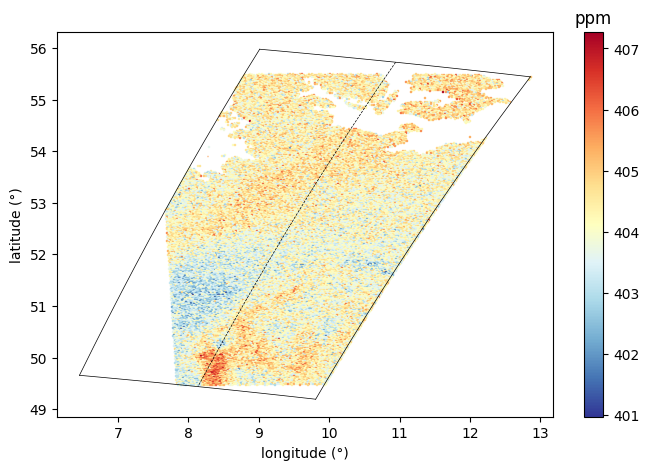

In [4]:
plot_overpass(overpass)

In [5]:
along_track_coords = compute_along_track(overpass)
along_track = np.asarray(Earth.inverse(along_track_coords[:-1],along_track_coords[1:]))
y = along_track[:,0] / 1000
along_track_dists = np.append([0.0],np.cumsum(y))
'''
plt.figure()
plt.plot(*np.vstack((overpass['lon'][0,:].data,overpass['lat'][0,:].data)),'k.',markersize=1.0)
plt.plot(*along_track_coords[0],'r.',markersize=1.5)
plt.plot(*np.vstack((overpass['lon'][1,:].data,overpass['lat'][1,:].data)),'k.',markersize=1.0)
plt.plot(*along_track_coords[1],'r.',markersize=1.5)
plt.plot(*np.vstack((overpass['lon'][2,:].data,overpass['lat'][2,:].data)),'k.',markersize=1.0)
plt.plot(*along_track_coords[2],'r.',markersize=1.5)
plt.xlim(17.5,18.5)
plt.ylim(60.2,60.3)
plt.show()
sys.exit()
'''

along_track_bearings = np.append(along_track[:,1],along_track[-1,2])
along_track_bearings[along_track_bearings < 0.0] += 360
cross_xr = xr.DataArray(data=np.full((overpass.dims['nobs'],overpass.dims['nrows']),np.nan,dtype=np.float32),
                        dims=['nobs','nrows'])
along_xr = xr.DataArray(data=np.full((overpass.dims['nobs'],overpass.dims['nrows']),np.nan,dtype=np.float32),
                        dims=['nobs','nrows'])

for nobs in range(overpass.dims['nobs']):
    cross_track_coords = np.column_stack((overpass['lon'][nobs,:].data,overpass['lat'][nobs,:].data))
    # Find the index of the closest point ot the center line
    idx = np.argmin(np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords))[:,0])

    # Calculate bearings to cross-track directions from the center line
    west_bearing = np.asarray(Earth.inverse(cross_track_coords[1:(idx+1)][::-1],cross_track_coords[0:idx][::-1]))[:,1]
    west_bearing[west_bearing < 0.0] += 360.0
    east_bearing = np.asarray(Earth.inverse(cross_track_coords[idx:-1],cross_track_coords[(idx+1):]))[:,1]
    east_bearing[east_bearing < 0.0] += 360.0
    # Calculate angles of cross-track directions measured from the along-track direction (clockwise direction as positive)
    west_angle = west_bearing - along_track_bearings[nobs]
    west_angle[west_angle > 180.0] -= 360.0
    west_angle[west_angle < -180.0] += 360.0
    west_angle_mean = west_angle.mean()
    east_angle = east_bearing - along_track_bearings[nobs]
    east_angle[east_angle > 180.0] -= 360.0
    east_angle[east_angle < -180.0] += 360.0
    east_angle_mean = east_angle.mean()
    
    nearest_bearing = np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[0,1]
    nearest_bearing += 360.0 if nearest_bearing < 0.0 else 0.0
    nearest_angle = nearest_bearing - along_track_bearings[nobs]
    if nearest_angle > 180.0:
        nearest_angle -= 360.0
    elif nearest_angle < -180.0:
        nearest_angle += 360.0
    # Equivalent to satelite heading towards north and positive x direction (roughly) towards east
    if west_angle_mean < 0.0 and east_angle_mean > 0.0:
        # Equivalent to the closest point in cross-track coordinates being west from along-track center line
        if abs(nearest_angle-west_angle_mean) < abs(nearest_angle-east_angle_mean):
            nearest_dist_pos = np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx+1]))[:,0]/1000
            nearest_dist_neg = -np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[:,0]/1000
            pos_dist = np.asarray(Earth.inverse(cross_track_coords[(idx+1):-1],cross_track_coords[(idx+2):]))[:,0]/1000
            neg_dist = -np.asarray(Earth.inverse(cross_track_coords[1:(idx+1)][::-1],cross_track_coords[0:idx][::-1]))[:,0]/1000
            dists = np.concatenate((np.cumsum(np.append(nearest_dist_neg,neg_dist))[::-1],np.cumsum(np.append(nearest_dist_pos,pos_dist))))
        # Equivalent to the closest point in cross-track coordinates being east from along-track center line
        else:
            nearest_dist_pos = np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[:,0]/1000
            nearest_dist_neg = -np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx-1]))[:,0]/1000
            pos_dist = np.asarray(Earth.inverse(cross_track_coords[idx:-1],cross_track_coords[(idx+1):]))[:,0]/1000
            neg_dist = -np.asarray(Earth.inverse(cross_track_coords[1:idx][::-1],cross_track_coords[0:(idx-1)][::-1]))[:,0]/1000
            dists = np.concatenate((np.cumsum(np.append(nearest_dist_neg,neg_dist))[::-1],np.cumsum(np.append(nearest_dist_pos,pos_dist))))
    # Equivalent to satellite heading towards south and positive x direction (roughly) towards west
    elif west_angle_mean > 0.0 and east_angle_mean < 0.0:
        # Equivalent to the closest point in cross-track coordinates being west from along-track center line
        if abs(nearest_angle-west_angle_mean) < abs(nearest_angle-east_angle_mean):
            nearest_dist_pos = np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[:,0]/1000
            nearest_dist_neg = -np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx+1]))[:,0]/1000
            pos_dist = np.asarray(Earth.inverse(cross_track_coords[1:idx][::-1],cross_track_coords[0:(idx-1)][::-1]))[:,0]/1000
            neg_dist = -np.asarray(Earth.inverse(cross_track_coords[idx:-1],cross_track_coords[(idx+1):]))[:,0]/1000
            dists = np.concatenate((np.cumsum(np.append(nearest_dist_pos,pos_dist))[::-1],np.cumsum(np.append(nearest_dist_neg,neg_dist))))
        # Equivalent to the closest point in cross-track coordinates being east from along-track center line
        else:
            nearest_dist_pos = np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx-1]))[:,0]/1000
            nearest_dist_neg = -np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[:,0]/1000
            pos_dist = np.asarray(Earth.inverse(cross_track_coords[1:(idx+1)][::-1],cross_track_coords[0:idx][::-1]))[:,0]/1000
            neg_dist = -np.asarray(Earth.inverse(cross_track_coords[(idx+1):-1],cross_track_coords[(idx+2):]))[:,0]/1000
            dists = np.concatenate((np.cumsum(np.append(nearest_dist_pos,pos_dist))[::-1],np.cumsum(np.append(nearest_dist_neg,neg_dist))))
    # Problem occured, maybe too close to the north or south pole
    else:
        raise ValueError('Unable to determine cross-track directions')
    #print(dists)
    #sys.exit()
    cross_xr.loc[dict(nobs=nobs)] = dists
    along_xr.loc[dict(nobs=nobs)] = np.repeat(along_track_dists[nobs],overpass.dims['nrows'])
overpass['cross_track'] = cross_xr
overpass['along_track'] = along_xr
CO2_data = overpass['CO2'][:,:].data

In [6]:
overpass

<xarray.Dataset> Size: 4MB
Dimensions:      (nobs: 364, nrows: 123, ncorners: 4)
Dimensions without coordinates: nobs, nrows, ncorners
Data variables: (12/16)
    lon          (nobs, nrows) float32 179kB 9.013 9.046 9.079 ... 9.78 9.808
    lat          (nobs, nrows) float32 179kB 55.98 55.97 55.97 ... 49.2 49.19
    lonc         (nobs, nrows, ncorners) float32 716kB 9.001 9.034 ... 9.79
    latc         (nobs, nrows, ncorners) float32 716kB 55.99 55.98 ... 49.19
    clouds       (nobs, nrows) float32 179kB nan nan nan nan ... nan nan nan nan
    psurf        (nobs, nrows) float32 179kB nan nan nan nan ... nan nan nan nan
    ...           ...
    CO2_std      (nobs, nrows) float32 179kB 0.7 0.7 0.7 0.7 ... 0.7 0.7 0.7 0.7
    NO2          (nobs, nrows) float32 179kB nan nan nan nan ... nan nan nan nan
    NO2_std      (nobs, nrows) float32 179kB 2e+15 2e+15 2e+15 ... 2e+15 2e+15
    time         datetime64[ns] 8B 2015-12-10T11:00:00
    cross_track  (nobs, nrows) float32 179kB 126.1 124.0 121.9 ... -120.4 -122.5
    along_track  (nobs, nrows) float32 179kB 0.0 0.0 0.0 ... 724.9 724.9 724.9
Attributes:
    satellite:    CO2M
    orbit:        5114
    lon_eq:       0
    DESCRIPTION:  Synthetic XCO2 and NO2 satellite image with auxiliary data ...
    DATAORIGIN:   SMARTCARB study
    DOI:          10.5281/zenodo.4048227
    CREATOR:      Gerrit Kuhlmann et al.
    EMAIL:        gerrit.kuhlmann@empa.ch
    AFFILIATION:  Empa Duebendorf, Switzerland

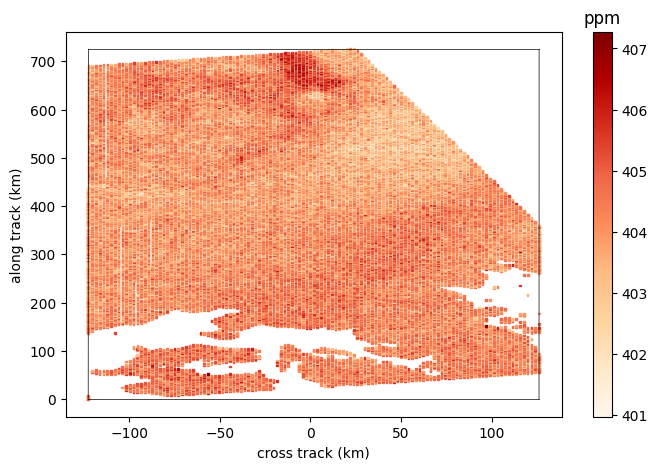

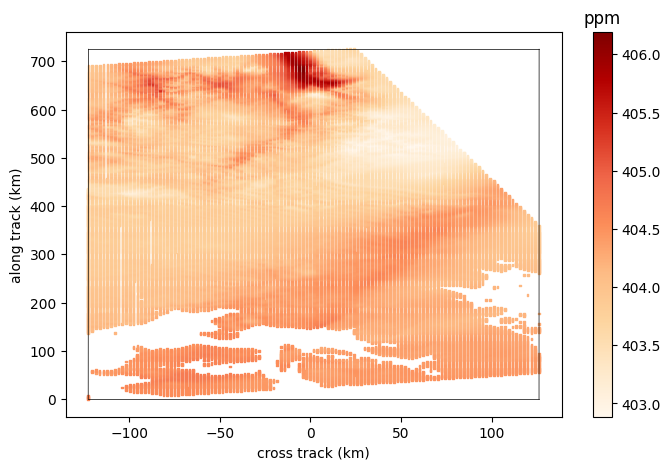

In [7]:
plt.figure(figsize=(8,5))
scatter = plt.scatter(overpass['cross_track'][:,:].data.flatten(),overpass['along_track'][:,:].data.flatten(),
                      c=CO2_data.flatten(),cmap='OrRd',marker='s',s=1.5)
cbar = plt.colorbar(mappable=scatter)
cbar.ax.set_title('ppm')

plt.plot(overpass['cross_track'][0,:].data,overpass['along_track'][0,:].data,
         linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['cross_track'][-1,:].data,overpass['along_track'][-1,:].data,
         linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['cross_track'][:,0].data,overpass['along_track'][:,0].data,
         linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['cross_track'][:,-1].data,overpass['along_track'][:,-1].data,
         linestyle='-',color='black',linewidth=0.5)

plt.xlabel('cross track (km)')
plt.ylabel('along track (km)')
plt.show()

BG_data = overpass['CO2_BG'][:,:].data
BG_data[np.isnan(CO2_data)] = np.NaN

plt.figure(figsize=(8,5))
scatter = plt.scatter(overpass['cross_track'][:,:].data.flatten(),overpass['along_track'][:,:].data.flatten(),
                      c=BG_data.flatten(),cmap='OrRd',marker='s',s=1.5)
cbar = plt.colorbar(mappable=scatter)
cbar.ax.set_title('ppm')

plt.plot(overpass['cross_track'][0,:].data,overpass['along_track'][0,:].data,
         linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['cross_track'][-1,:].data,overpass['along_track'][-1,:].data,
         linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['cross_track'][:,0].data,overpass['along_track'][:,0].data,
         linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['cross_track'][:,-1].data,overpass['along_track'][:,-1].data,
         linestyle='-',color='black',linewidth=0.5)

plt.xlabel('cross track (km)')
plt.ylabel('along track (km)')
plt.show()

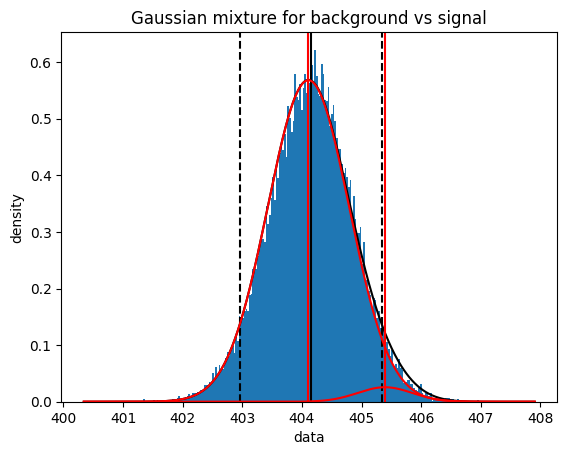

In [8]:
def estimate_bg(data,return_std=False,sigma_scale=1.96,mixture=True,plot=False):
    if data.ndim > 1:
        data = data.flatten()
    data = data[~np.isnan(data)]
    '''
    # Remove clear outliers
    data_mean, data_std = data.mean(), data.std(ddof=1)
    outlier_mask = (data < data_mean-(sigma_scale+1.0)*data_std) & (data > data_mean+(sigma_scale+1.0)*data_std)
    data = data[~outlier_mask]
    '''
    mean, std = data.mean(), data.std(ddof=1)
    area = norm.cdf(mean+sigma_scale*std,mean,std) - norm.cdf(mean-sigma_scale*std,mean,std)
    while True:
        mask = (mean-sigma_scale*std < data) & (data < mean+sigma_scale*std)
        mean, std = data[mask].mean(), data[mask].std(ddof=1)
        if sum(mask) / len(mask) < area or len(mask) == len(mask):
            break
    
    if plot and not mixture:
        xmin, xmax = data.min(), data.max()
        x = np.linspace(xmin-0.1*(xmax-xmin),xmax+0.1*(xmax-xmin), 1000)
        plt.hist(data,bins=int(np.ceil(np.sqrt(1.5*len(data)))),density=True,label='data')
        plt.plot(x, norm.pdf(x,data_mean,data_std), '-k', label='original')
        plt.axvline(x=data.mean(),color='k',linestyle='--')
        plt.plot(x, norm.pdf(x,mean,std), '-r', label='filtered')
        plt.axvline(x=mean,color='r',linestyle='--')
        plt.legend()
        plt.show()
    if mixture:
        mask = data > mean+sigma_scale*std
        if sum(mask) == 0:
            means_init = np.reshape([mean,data.max()],(-1,1))
            precisions_init = np.reshape([1/std**2,1/std**2],(-1,1))
        elif sum(mask) == 1:
            means_init = np.reshape([mean,data[mask].mean()],(-1,1))
            precisions_init = np.reshape([1/std**2,1/std**2],(-1,1))
        else:
            means_init = np.reshape([mean,data[mask].mean()],(-1,1))
            precisions_init = np.reshape([1/std**2,1/data[mask].std(ddof=1)**2],(-1,1))
        weights_init = np.array([0.9,0.1])
        model = GaussianMixture(n_components=2,covariance_type='diag',weights_init=weights_init,
                                means_init=means_init,precisions_init=precisions_init)
        model.fit(data.reshape((-1,1)))
        means = model.means_.squeeze()
        sort_ind = np.argsort(means)
        means = means[sort_ind]
        stds = np.sqrt(model.covariances_.squeeze())[sort_ind]
        if plot:
            xmin, xmax = data.min(), data.max()
            x = np.linspace(xmin-0.1*(xmax-xmin),xmax+0.1*(xmax-xmin), 1000)
            logprob = model.score_samples(x.reshape(-1, 1))
            responsibilities = model.predict_proba(x.reshape(-1, 1))
            pdf = np.exp(logprob)
            pdf_individual = responsibilities * pdf[:, np.newaxis]
            plt.hist(data, bins=int(np.ceil(np.sqrt(1.5*len(data)))), density=True)
            plt.plot(x, pdf, '-k')
            plt.axvline(x=mean,color='k',linestyle='-')
            plt.axvline(x=mean-sigma_scale*std,color='k',linestyle='--')
            plt.axvline(x=mean+sigma_scale*std,color='k',linestyle='--')
            plt.plot(x, pdf_individual, '-r')
            plt.axvline(x=means[0],color='r',linestyle='-')
            plt.axvline(x=means[1],color='r',linestyle='-')
            plt.xlabel('data')
            plt.ylabel('density')
            plt.title('Gaussian mixture for background vs signal')
            plt.show()
        mean, std = means[0], stds[0]
    if return_std:
        return mean,std
    else:
        return mean

bg_mean, bg_std = estimate_bg(overpass['CO2'][:,:].data,return_std=True,plot=True)

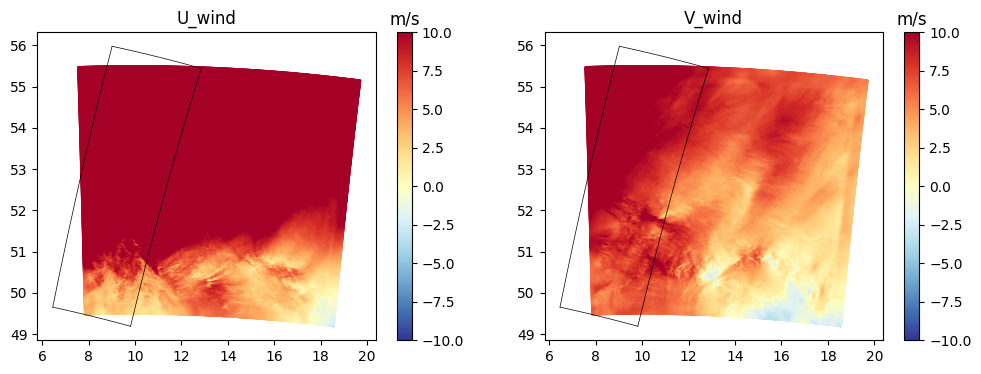

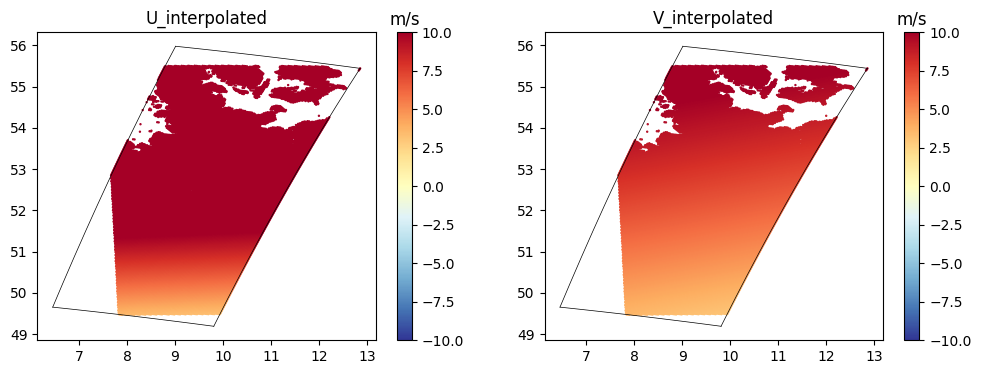

In [9]:
# Include wind to the overpass
YYYYmmdd = f'{overpass.time.dt.strftime("%Y%m%d").data}'
wind_name = f'SMARTCARB_winds_{YYYYmmdd}11.nc'
with xr.open_dataset(os.path.join(WIND_DATA_PATH,wind_name)) as wind:
    wlon, wlat = wind['lon'].data.flatten(), wind['lat'].data.flatten()
    fig_wind, (ax_U,ax_V) = plt.subplots(nrows=1,ncols=2,figsize=(12,4))
    ax_U.set_title('U_wind');ax_V.set_title('V_wind')
    ax_U.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
         linestyle='-',color='black',linewidth=0.5)
    ax_U.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_U.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_U.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_V.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
         linestyle='-',color='black',linewidth=0.5)
    ax_V.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_V.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_V.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
             linestyle='-',color='black',linewidth=0.5)
    U,V = wind['U_GNFR_A'].data.flatten(), wind['V_GNFR_A'].data.flatten()
    scatter_U = ax_U.scatter(wlon,wlat,c=U,cmap='RdYlBu_r',s=0.5,
                             vmin=-10.0,vmax=10.0)
    cbar_U = plt.colorbar(mappable=scatter_U,ax=ax_U)
    cbar_U.ax.set_title('m/s')
    scatter_V = ax_V.scatter(wlon,wlat,c=V,cmap='RdYlBu_r',s=0.5,
                             vmin=-10.0,vmax=10.0)
    non_nans = ~np.isnan(overpass['CO2'].data.flatten())
    cbar_V = plt.colorbar(mappable=scatter_V,ax=ax_V)
    cbar_V.ax.set_title('m/s')
    # Find the interpolating spline using SciPy. With the chosen weights, the square sum of weights is exactly
    # one and the function to be optimized is the mean square distance between the data and the spline
    U_interpolator = SmoothSphereBivariateSpline(np.deg2rad(90.0-wlat.flatten()),np.deg2rad(wlon.flatten()),U,
                                                 w=np.ones(len(U))/np.sqrt(len(U)),s=1e-5*len(U))
    V_interpolator = SmoothSphereBivariateSpline(np.deg2rad(90.0-wlat.flatten()),np.deg2rad(wlon.flatten()),V,
                                                 w=np.ones(len(V))/np.sqrt(len(V)),s=1e-5*len(V))
    lon, lat = overpass['lon'].data.flatten(), overpass['lat'].data.flatten()
    U_interp = np.full(overpass.dims['nobs']*overpass.dims['nrows'],np.nan)
    U_interp[non_nans] = U_interpolator.ev(np.deg2rad(90.0-lat[non_nans]),np.deg2rad(lon[non_nans]))
    U_interp = U_interp.reshape((overpass.dims['nobs'],overpass.dims['nrows']))
    V_interp = np.full(overpass.dims['nobs']*overpass.dims['nrows'],np.nan)
    V_interp[non_nans] = V_interpolator.ev(np.deg2rad(90.0-lat[non_nans]),np.deg2rad(lon[non_nans]))
    V_interp = V_interp.reshape((overpass.dims['nobs'],overpass.dims['nrows']))
    plt.show()
    
    fig_interp, (ax_U_interp,ax_V_interp) = plt.subplots(nrows=1,ncols=2,figsize=(12,4))
    ax_U_interp.set_title('U_interpolated');ax_V_interp.set_title('V_interpolated')
    ax_U_interp.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
         linestyle='-',color='black',linewidth=0.5)
    ax_U_interp.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_U_interp.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_U_interp.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_V_interp.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
         linestyle='-',color='black',linewidth=0.5)
    ax_V_interp.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_V_interp.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
             linestyle='-',color='black',linewidth=0.5)
    ax_V_interp.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
             linestyle='-',color='black',linewidth=0.5)
    scatter_U_interp = ax_U_interp.scatter(lon,lat,c=U_interp,cmap='RdYlBu_r',s=0.5,
                                           vmin=-10.0,vmax=10.0)
    cbar_U_interp = plt.colorbar(mappable=scatter_U_interp,ax=ax_U_interp)
    cbar_U_interp.ax.set_title('m/s')
    scatter_V_interp = ax_V_interp.scatter(lon,lat,c=V_interp,cmap='RdYlBu_r',s=0.5,
                                           vmin=-10.0,vmax=10.0)
    cbar_V_interp = plt.colorbar(mappable=scatter_V_interp,ax=ax_V_interp)
    cbar_V_interp.ax.set_title('m/s')
    plt.show()

In [10]:
#vx = np.full(overpass.dims['nobs']*overpass.dims['nrows'],np.nan)
#vy = np.full(overpass.dims['nobs']*overpass.dims['nrows'],np.nan)
vy_xr = xr.DataArray(data=np.full((overpass.dims['nobs'],overpass.dims['nrows']),np.nan,dtype=np.float32),
                     dims=['nobs','nrows'])
vx_xr = xr.DataArray(data=np.full((overpass.dims['nobs'],overpass.dims['nrows']),np.nan,dtype=np.float32),
                     dims=['nobs','nrows'])

for nobs in range(overpass.dims['nobs']):
    non_nans = ~np.isnan(CO2_data[nobs,:])
    # If all values are nan, move forward
    if np.sum(non_nans) == 0:
        continue
    cross_track_coords = np.column_stack((overpass['lon'][nobs,:].data,overpass['lat'][nobs,:].data))
    # Find the index of the closest point ot the center line
    idx = np.argmin(np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords))[:,0])
    # Check if the nearest point is to the east or west
    nearest_bearing = np.asarray(Earth.inverse(along_track_coords[nobs],cross_track_coords[idx]))[0,1]
    nearest_bearing = nearest_bearing + 360.0 if nearest_bearing < 0.0 else nearest_bearing
    # Initialize rotation matrices
    R = np.full((np.sum(non_nans),2,2),np.nan)
    # Nearest point from the center track is to west
    if nearest_bearing > along_track_bearings[nobs]:
        bearing = np.asarray(Earth.inverse(cross_track_coords[idx],along_track_coords[nobs]))[0,1]
        bearing = bearing + 360.0 if nearest_bearing < 0.0 else bearing
        west_bearing = np.append(np.asarray(Earth.inverse(cross_track_coords[:idx],cross_track_coords[1:(idx+1)]))[:,1],
                                 bearing)
        west_bearing[west_bearing < 0.0] += 360.0
        bearing = np.asarray(Earth.inverse(cross_track_coords[idx+1],along_track_coords[nobs]))[0,1]
        bearing = bearing + 360.0 if nearest_bearing < 0.0 else bearing
        east_bearing = np.append(np.asarray(Earth.inverse(cross_track_coords[(idx+2):][::-1],cross_track_coords[(idx+1):-1][::-1]))[:,1],
                                 bearing)
        east_bearing[east_bearing < 0.0] += 360.0
        # Array length of the west bearings is one more than the array length of the east bearings
        non_nan_indices = np.where(non_nans)[0]
    # Nearest point from the center track is to east
    else:
        bearing = np.asarray(Earth.inverse(cross_track_coords[idx-1],along_track_coords[nobs]))[0,1]
        bearing = bearing + 360.0 if nearest_bearing < 0.0 else bearing
        west_bearing = np.append(np.asarray(Earth.inverse(cross_track_coords[:(idx-1)],cross_track_coords[1:idx]))[:,1],
                                 bearing)
        west_bearing[west_bearing < 0.0] += 360.0
        bearing = np.asarray(Earth.inverse(cross_track_coords[idx],along_track_coords[nobs]))[0,1]
        bearing = bearing + 360.0 if nearest_bearing < 0.0 else bearing
        east_bearing = np.append(np.asarray(Earth.inverse(cross_track_coords[(idx+1):][::-1],cross_track_coords[idx:-1][::-1]))[:,1],
                                 bearing)
        # Array length of the east bearings is one more than the array length of the west bearings
    non_nan_indices = np.where(non_nans)[0]
    non_nans_to_west = non_nan_indices < len(west_bearing)
    if np.sum(non_nans_to_west) > 0:
        R[non_nans_to_west,0,0] = np.cos(np.deg2rad(270-west_bearing[non_nan_indices[non_nans_to_west]]))
        R[non_nans_to_west,0,1] = -np.sin(np.deg2rad(270-west_bearing[non_nan_indices[non_nans_to_west]]))
        R[non_nans_to_west,1,0] = np.sin(np.deg2rad(270-west_bearing[non_nan_indices[non_nans_to_west]]))
        R[non_nans_to_west,1,1] = np.cos(np.deg2rad(270-west_bearing[non_nan_indices[non_nans_to_west]]))
    non_nans_to_east = non_nan_indices >= len(east_bearing) - 1
    if np.sum(non_nans_to_east) > 0:
        R[non_nans_to_east,0,0] = np.cos(np.deg2rad(90-east_bearing[non_nan_indices[non_nans_to_east]-len(west_bearing)]))
        R[non_nans_to_east,0,1] = -np.sin(np.deg2rad(90-east_bearing[non_nan_indices[non_nans_to_east]-len(west_bearing)]))
        R[non_nans_to_east,1,0] = np.sin(np.deg2rad(90-east_bearing[non_nan_indices[non_nans_to_east]-len(west_bearing)]))
        R[non_nans_to_east,1,1] = np.cos(np.deg2rad(90-east_bearing[non_nan_indices[non_nans_to_east]-len(west_bearing)]))
    
    # Get U and V components of the wind and gather them to a matrix (column vectors as wind vectors)
    wind_vecs = np.vstack((U_interp[nobs,non_nans],V_interp[nobs,non_nans]))
    rotated_wind_vecs = np.einsum('ijk,ki->ij', R, wind_vecs)
    vx_xr.loc[dict(nobs=nobs,nrows=non_nan_indices)] = rotated_wind_vecs[:,0]
    vy_xr.loc[dict(nobs=nobs,nrows=non_nan_indices)] = rotated_wind_vecs[:,1]
overpass['vy'] = vy_xr
overpass['vx'] = vx_xr

In [11]:
groundtruth = overpass['CO2_BG']

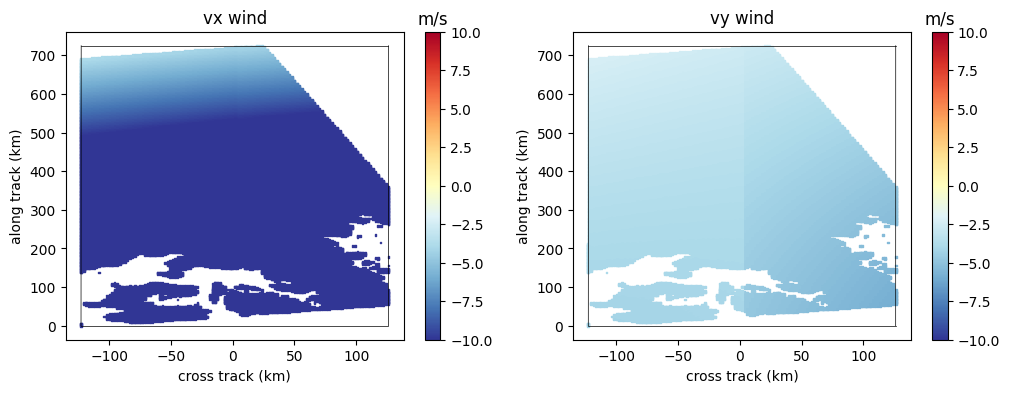

In [12]:
fig_wind, (ax_vx,ax_vy) = plt.subplots(nrows=1,ncols=2,figsize=(12,4))
scatter_vx = ax_vx.scatter(overpass['cross_track'][:,:].data.flatten(),overpass['along_track'][:,:].data.flatten(),
                      c=overpass['vx'][:,:].data.flatten(),cmap='RdYlBu_r',vmin=-10.0,vmax=10.0,marker='s',s=1.5)
scatter_vy = ax_vy.scatter(overpass['cross_track'][:,:].data.flatten(),overpass['along_track'][:,:].data.flatten(),
                      c=overpass['vy'][:,:].data.flatten(),cmap='RdYlBu_r',vmin=-10.0,vmax=10.0,marker='s',s=1.5)
cbar_vx = plt.colorbar(mappable=scatter_vx,ax=ax_vx)
cbar_vx.ax.set_title('m/s')
scatter_V = ax_V.scatter(wlon,wlat,c=V,cmap='RdYlBu_r',s=0.5,
                         vmin=-10.0,vmax=10.0)
cbar_vy = plt.colorbar(mappable=scatter_vy,ax=ax_vy)
cbar_vy.ax.set_title('m/s')
for ax in (ax_vx,ax_vy):
    ax.plot(overpass['cross_track'][0,:].data,overpass['along_track'][0,:].data,
             linestyle='-',color='black',linewidth=0.5)
    ax.plot(overpass['cross_track'][-1,:].data,overpass['along_track'][-1,:].data,
             linestyle='-',color='black',linewidth=0.5)
    ax.plot(overpass['cross_track'][:,0].data,overpass['along_track'][:,0].data,
             linestyle='-',color='black',linewidth=0.5)
    ax.plot(overpass['cross_track'][:,-1].data,overpass['along_track'][:,-1].data,
             linestyle='-',color='black',linewidth=0.5)
    ax.set_xlabel('cross track (km)')
    ax.set_ylabel('along track (km)')
ax_vx.set_title('vx wind')
ax_vy.set_title('vy wind')
plt.show()

In [244]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel


image = overpass['CO2'][:,:].data

def gp_denoise(image, length_scale=0.5, sigma=0.7):
    
    X = np.column_stack((overpass['cross_track'][:,:].data.flatten(), overpass['along_track'][:,:].data.flatten()))
    y = image.flatten()

    non_nan_idx = ~np.isnan(y)
    y_train, X_train = y[non_nan_idx], X[non_nan_idx]

    indices = np.random.choice(range(len(y_train)),replace=False,size=len(y_train)//4)
    # Define the kernel: RBF (smoothness) + WhiteKernel (noise)
    kernel = RBF(length_scale=length_scale) + WhiteKernel(noise_level=sigma)

    # Fit the Gaussian Process
    gp = GaussianProcessRegressor(kernel=kernel,alpha=0)
    gp.fit(X_train[indices], y_train[indices]-bg_mean)

    # Predict the denoised image
    y_pred, _ = gp.predict(X_train, return_std=True)
    y[non_nan_idx] = y_pred+bg_mean
    return y.reshape((overpass.dims['nobs'],overpass.dims['nrows']))
#result = image
#result = gp_denoise(image, sigma=bg_std)
X_full = np.column_stack((overpass['cross_track'][:,:].data.flatten(),
                          overpass['along_track'][:,:].data.flatten()))
z_full = image.flatten()
is_non_nan = ~np.isnan(z_full)
z, X = z_full[is_non_nan], X_full[is_non_nan]

#indices = sorted(np.random.choice(range(len(z)),replace=False,size=len(z)//2))
#X_train = X[indices]
#z_train = z[indices]-bg_mean

X_train = X
z_train = z-bg_mean
image.shape

(364, 123)

In [274]:
def add_sparse(*mats,sparse_format='dia',dtype=np.float32):
    if len(mats) == 1:
        return mats[0]
    if sparse_format == 'dia':
        if mats[0].format != sparse_format:
            raise ValueError(f'First matrix of the addition is not in {sparse_format} format')
        offsets = mats[0].offsets
        shape = mats[0].shape
        for n in range(1, len(mats)):
            if any(mats[n].offsets != offsets):
                raise ValueError(f"Matrix at argument ({n}) is not in '{sparse_format}' format")
            elif mats[n].shape != shape:
                raise ValueError(f"Matrix at argument ({n}) has different shape than previous arguments")
            elif any(mats[n].offsets != offsets):
                raise ValueError(f"Matrix at argument ({n}) has different offsets than")
        return dia_matrix((sum([mat.data for mat in mats]),offsets),shape,dtype=dtype)
    elif sparse_format in ['bsr','coo','csc','csr','dok','lil']:
        raise ValueError(f'Sparse format {sparse_format} not supported for sparse addition')
    else:
        raise ValueError(f'Unknown sparse format {sparse_format}')
        
def multiply_sparse(*mats,sparse_format='dia',dtype=np.float32):
    if len(mats) == 1:
        return mats[0]
    if sparse_format == 'dia':
        if mats[0].format != sparse_format:
            raise ValueError(f'First matrix of the multiplication is not in {sparse_format} format')
        offsets = mats[0].offsets
        shape = mats[0].shape
        for n in range(1, len(mats)):
            if mats[n].format != sparse_format:
                raise ValueError(f"Matrix at argument ({n}) is not in '{sparse_format}' format")
            elif mats[n].shape != shape:
                raise ValueError(f"Matrix at argument ({n}) has different shape than previous arguments")
            elif any(mats[n].offsets != offsets):
                raise ValueError(f"Matrix at argument ({n}) has different offsets than")
        return dia_matrix((prod([mat.data for mat in mats]),offsets),shape,dtype=dtype)
    elif sparse_format in ['bsr','coo','csc','csr','dok','lil']:
        raise ValueError(f'Sparse format {sparse_format} not supported for multiplication')
    else:
        raise ValueError(f'Unknown sparse format {sparse_format}')

def ufunc_sparse(mat,ufunc,sparse_format='dia',ignore_zeros=True,exceptions=[]):
    if sparse_format == 'dia':
        offsets = mat.offsets.tolist()
        shape = mat.shape
        data = mat.data
        if ignore_zeros:
            iszero = data == 0.0
            # Map all values with ufunc, ignore zeros if ignore_zeros is True
            mapped_data = np.zeros(data.shape,dtype=mat.dtype)
            mapped_data[~iszero] = ufunc(data[~iszero])
            # For diagonal format, a value in a list of exceptions corresponds to offset
            for offset in exceptions:
                exception_index = offsets.index(offset)
                mapped_data[exception_index,:] = ufunc(data[exception_index,:])
        else:
            mapped_data = ufunc(data)
            for offset in exceptions:
                exception_index = offsets.index(offset)
                mapped_data[exception_index,:] = np.zeros(data.shape[1])
        return dia_matrix((mapped_data,offsets),shape)
    elif sparse_format in ['bsr','coo','csc','csr','dok','lil']:
        raise ValueError(f'Sparse format {sparse_format} not supported for multiplication')
    else:
        raise ValueError(f'Unknown sparse format {sparse_format}')

In [275]:
test_sparse = diags([[0,1,2,0],[0,0,0,0,0],[0,1,2,0],],offsets=[-1,0,1],shape=(5,5),dtype=np.float32)
mapped_sparse = ufunc_sparse(test_sparse,np.exp,exceptions=[0])
mapped_sparse.todense()

matrix([[1.       , 0.       , 0.       , 0.       , 0.       ],
        [0.       , 1.       , 2.718282 , 0.       , 0.       ],
        [0.       , 2.718282 , 1.       , 7.3890557, 0.       ],
        [0.       , 0.       , 7.3890557, 1.       , 0.       ],
        [0.       , 0.       , 0.       , 0.       , 1.       ]],
       dtype=float32)

In [280]:
def pairwise_distances(X, cov_tol=1e-3, min_lx=1.0, min_ly=1.0, dtype=np.float32, sparse_format='dia'):
    # Input guestimation for minimal lenght scales for x and y dimensions
    def fun(d):
        L = 1/min_lx**2+1/min_ly**2
        v = (1+0.5*np.sqrt(5/L)*d+5/12*d**2/L)*np.exp(-0.5*np.sqrt(5/L)*d)-cov_tol
        g = -5/12*d/L*(1+0.5*np.sqrt(5/L)*d)*np.exp(-0.5*np.sqrt(5/L)*d)
        return (v,g)
    # Threshold for distance; distances greater than thrsh have Matern covariance less than cov_tol
    thrsh = root(fun, x0=2*np.sqrt(1/min_lx**2+1/min_ly**2), jac=True, tol=1e-6).x
    # Construct pair-wise distances as nd-array
    dx = (X[:, np.newaxis, 0] - X[np.newaxis, :, 0]).astype(dtype)
    dy = (X[:, np.newaxis, 1] - X[np.newaxis, :, 1]).astype(dtype)
    # Convert to sparse format
    if sparse_format == 'dia':
        # Diagonals where all values are greater than or equal to thrsh are omitted
        offsets = []
        dx_arrs, dy_arrs = [], []
        for offset in range(-len(X),len(X)):
            dx_diagonal = np.diag(dx,k=offset)
            dy_diagonal = np.diag(dy,k=offset)
            if np.any(dx_diagonal**2+dy_diagonal**2 < thrsh**2):
                offsets.append(offset)
                dx_arrs.append(dx_diagonal)
                dy_arrs.append(dy_diagonal)
        offsets = np.array(offsets,dtype=np.int32)
        dx_sparse = diags(dx_arrs,offsets=offsets,format='dia',dtype=dtype)
        dy_sparse = diags(dy_arrs,offsets=offsets,format='dia',dtype=dtype)
    elif sparse_format in ['bsr','coo','csc','csr','dok','lil']:
        raise ValueError(f'Sparse format {sparse_format} not supported')
    else:
        raise ValueError(f'Unknown sparse format {sparse_format}')
    return dx_sparse, dy_sparse

def distance_matrix(dx, dy, lx=1.0, ly=1.0, alpha=0.0, dtype=np.float32):
    cosa = np.cos(alpha,dtype=dtype)
    sina = np.sin(alpha,dtype=dtype)
    d_squared = add_sparse((add_sparse(dx*cosa,-dy*sina).power(2)/lx**2).astype(dtype),
                           (add_sparse(dx*sina,dy*cosa).power(2)/ly**2).astype(dtype))
    return d_squared.sqrt()

def Matern(dx,dy,lx=1.0,ly=1.0,alpha=0.0,sigma=0.3,nu='5/2',dtype=np.float32):
    d_mat = distance_matrix(dx, dy, dtype=dtype)
    offsets = d_mat.offsets
    N = d_mat.shape[0]
    ones_sparse = diags([np.ones(N-abs(offset),dtype=dtype) for offset in offsets],
                        offsets=offsets,format='dia',dtype=dtype)
    if nu == '5/2':
        return sigma**2*multiply_sparse(add_sparse(ones_sparse,np.sqrt(5)*d_mat,5/3*d_mat.power(2)),
                                        ufunc_sparse(-np.sqrt(5)*d_mat,np.exp,exceptions=[0]))
    else:
        raise ValueError(f'Option nu={nu} not implemented')

In [282]:
dx, dy = pairwise_distances(X, min_lx=0.5, min_ly=0.5)

In [285]:
d_mat = distance_matrix(dx, dy)
d_mat.todense()

matrix([[0.       , 1.9978334, 3.9955962, ..., 0.       , 0.       ,
         0.       ],
        [1.9978334, 0.       , 1.9977629, ..., 0.       , 0.       ,
         0.       ],
        [3.9955962, 1.9977629, 0.       , ..., 0.       , 0.       ,
         0.       ],
        ...,
        [0.       , 0.       , 0.       , ..., 0.       , 2.0092106,
         4.0179253],
        [0.       , 0.       , 0.       , ..., 2.0092106, 0.       ,
         2.0087147],
        [0.       , 0.       , 0.       , ..., 4.0179253, 2.0087147,
         0.       ]], dtype=float32)

In [286]:
M = Matern(dx,dy)
M_dense = M.todense()
M_dense

matrix([[0.09      , 0.01252011, 0.00043338, ..., 0.        , 0.        ,
         0.        ],
        [0.01252011, 0.09      , 0.01252143, ..., 0.        , 0.        ,
         0.        ],
        [0.00043338, 0.01252143, 0.09      , ..., 0.        , 0.        ,
         0.        ],
        ...,
        [0.        , 0.        , 0.        , ..., 0.09      , 0.01230775,
         0.0004162 ],
        [0.        , 0.        , 0.        , ..., 0.01230775, 0.09      ,
         0.01231694],
        [0.        , 0.        , 0.        , ..., 0.0004162 , 0.01231694,
         0.09      ]], dtype=float32)

In [ ]:
#from sksparse.cholmod import cholsesky
import scipy.sparse as sp
import scipy.sparse.linalg as spla
from scipy.sparse.linalg import splu


def compute_logDet(K):
    lu = splu(K)
    diagL = lu.L.diagonal()
    diagU = lu.U.diagonal()
    return np.log(diagL).sum() + np.log(diagU).sum()

def loss_grad(Kinv_z,Kinv_d):
    return  -0.5 * z.T@Kinv_d@Kinv_z + 0.5 * diags(Kinv_d)

def hyper_grad(z,K,Kinv_z,d,dx,dy,lx,ly,alpha,sigma_f,sigma_n,dtype=np.float32):
    cosa = np.cos(alpha)
    sina = np.sin(alpha)
    n = len(z)
    K_noisy = K + sigma_n * sp.eye(n)
    
    print("nominator for dlx, dly and dla")
    dlx = (5*sigma_f**2 * (1+np.sqrt(5) * d))
    dly = dlx
    dla = dlx

    print("dlx")
    dlx /= (3*lx**3*np.exp(np.sqrt(5)*d))
    dlx *= (dx*cosa -dy*sina)**2
    print("Kinv_dlx")
    Kinv_dlx = spla.spsolve(K_noisy,dlx)
    print("x loss gradient")
    dlx = loss_grad(Kinv_z,Kinv_dlx)

    print("dK/dly")
    dly /= (3*ly**3*np.exp(np.sqrt(5)*d))
    dly *= (dx*sina + dy*cosa)**2
    print("Kinv_dly")
    Kinv_dly = spla.spsolve(K_noisy,dly)
    print("y loss gradient")
    dly = loss_grad(Kinv_z,Kinv_dly)

    print("dK/da")
    dla /= (3*np.exp(np.sqrt(5)*d))
    dla *= (1/ly**2 - 1/lx**2)*(dx*cosa - dy*sina)*(dx*sina+dy*cosa)
    print("Kinv_dla")
    Kinv_dla = spla.spsolve(K_noisy,dla)
    print("a loss gradient")
    dla = loss_grad(Kinv_z,Kinv_dla)

    print("dK/ds")
    dls = 2*sigma_f*K 
    print("Kinv_dls")
    Kinv_dls = spla.spsolve(K_noisy,dls)
    print("s loss gradient")
    dls = loss_grad(Kinv_z,Kinv_dls)

    return [dlx,dly,dla,dls]

def log_likelihood(params,dx,dy,z,sigma_n):
    lx,ly,alpha,sigma_f = params

    print("Computing K")
    d = distance_matrix(dx,dy,lx,ly,alpha)
    K = matern52(d,sigma_f)
    n = len(z)
    K_noisy = K + sigma_n * sp.eye(n)

    print("solving Kinvz and logdetK")
    Kinv_z = spla.spsolve(K_noisy,z)
    logdet_K = compute_logDet(K_noisy)

    print("Solving gradient")
    g = hyper_grad(z,K,Kinv_z,d,dx,dy,z,lx,ly,alpha,sigma_f,sigma_n)
    return 0.5 * z.T @ Kinv_z + 0.5 * logdet_K, g


# lx,ly, alpha, sigma_f
init_params = [4.0,4.0,0.0,1.0]
bounds = [(1e-8,15),(1e-8,15),(-np.pi/4,np.pi/4),(1e-5,2)]
sigma_n = bg_std**2
res = minimize(
    fun = log_likelihood,
    jac=True,
    x0=init_params,
    args=(dx,dy,z_train,sigma_n),
    method='L-BFGS-B',
    bounds=bounds,
    options={'disp':True}
)

print(res.x)
lx,ly,alpha,sigma_f = res.x

K = Matern(dx,dy,lx=lx,ly=ly,alpha=alpha,sigma=sigma_f,nu=5/2)

#print(K)
n = len(z)
K_noisy = K + sigma_n * sp.eye(n)
Kinv_z = spla.spsolve(K_noisy,z)

z_pred = K@Kinv_z+bg_mean

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            4     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  5.03969D+03    |proj g|=  7.85398D-01


In [ ]:
print(z_pred.shape)
z_full[is_non_nan] = z_pred
print(z_full.shape)
result = z_full.reshape(image.shape)
print(result.shape)
print(bg_std)

(33313,)
(44772,)
(364, 123)
0.6815460357872175


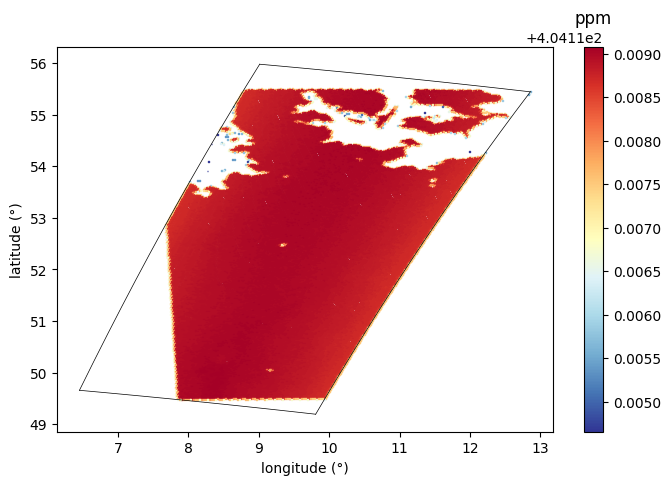

In [ ]:

fig = plt.figure(figsize=(8,5))
scatter = plt.scatter(overpass['lon'][:,:].data.flatten(),overpass['lat'][:,:].data.flatten(),
                        c=result.flatten(),cmap="RdYlBu_r",marker='s',s=0.5)
                        
cbar = plt.colorbar(mappable=scatter)
cbar.ax.set_title('ppm')
plt.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
            linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
            linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
            linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
            linestyle='-',color='black',linewidth=0.5)
#plt.plot(center_lon,center_lat,linestyle='--',color='red',linewidth=0.5)
plt.xlabel('longitude (°)')
plt.ylabel('latitude (°)')
plt.show()

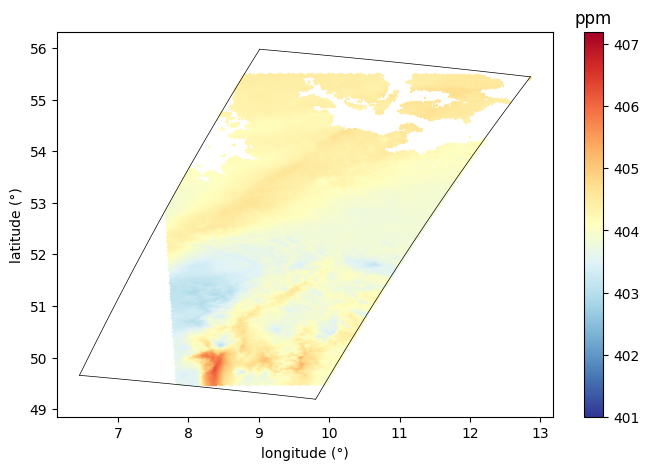

In [ ]:
fig = plt.figure(figsize=(8,5))
scatter = plt.scatter(overpass['lon'][:,:].data.flatten(),overpass['lat'][:,:].data.flatten(),
                        c=groundtruth.data.flatten(),cmap="RdYlBu_r",marker='s',s=0.5,vmin=401,vmax=407.2)
cbar = plt.colorbar(mappable=scatter)
cbar.ax.set_title('ppm')
plt.plot(overpass['lon'][0,:].data,overpass['lat'][0,:].data,
            linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['lon'][:,0].data,overpass['lat'][:,0].data,
            linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['lon'][-1,:].data,overpass['lat'][-1,:].data,
            linestyle='-',color='black',linewidth=0.5)
plt.plot(overpass['lon'][:,-1].data,overpass['lat'][:,-1].data,
            linestyle='-',color='black',linewidth=0.5)
#plt.plot(center_lon,center_lat,linestyle='--',color='red',linewidth=0.5)
plt.xlabel('longitude (°)')
plt.ylabel('latitude (°)')
plt.show()

In [ ]:
print(min(groundtruth.data.flatten()[~np.isnan(groundtruth.data.flatten())]))

402.88547
